# NumCompute-Stream demo
Run all cells from the repository or demo directory. Data is a bundled, seeded synthetic CSV (1,200 rows, three features, 2% missing values). Evaluation is prequential: predict before learning each evaluated chunk.

In [3]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'numcompute_stream').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from numcompute_stream import Pipeline, SimpleImputer, StandardScaler, DecisionTreeClassifier, StreamTrainer
from numcompute_stream.io import read_csv_chunks
from numcompute_stream.visualize import plot_metric_over_time, compare_models, plot_predictions_vs_ground_truth
chunks = list(read_csv_chunks(ROOT / 'demo/data/stream.csv', chunk_size=100, skip_header=1, dtype=float))
print(len(chunks), 'chunks:', chunks[0].shape)

12 chunks: (100, 4)


In [4]:
def make_trainer(size):
    return StreamTrainer(pipeline=Pipeline([
        ('impute', SimpleImputer()),
        ('scale', StandardScaler()),
        ('tree', DecisionTreeClassifier(max_depth=5, buffer_size=size)),
    ]))
trainers = [make_trainer(100), make_trainer(300)]
histories = [[], []]
# Both models warm up on the same 300 samples.
for trainer in trainers:
    warmup = np.concatenate(chunks[:3])
    trainer.model.fit(warmup[:, :-1], warmup[:, -1].astype(int))
for chunk in chunks[3:]:
    X, y = chunk[:, :-1], chunk[:, -1].astype(int)
    for trainer, history in zip(trainers, histories):
        trainer.score_chunk(X, y)
        history.append(trainer.logs[-1]['accuracy'])
        trainer.fit_chunk(X, y)
for trainer in trainers:
    print(trainer.metrics.result())
print('Latest log:', trainers[0].logs[-1])

{'accuracy': 0.9122222222222223, 'precision': 0.9134615384615384, 'recall': 0.9131447973864608, 'f1': 0.9122195129479305, 'confusion_matrix': array([[408,  55],
       [ 24, 413]]), 'classes': array([0, 1]), 'auc': nan, 'n_samples': 900}
{'accuracy': 0.9455555555555556, 'precision': 0.9455374090477697, 'recall': 0.9454779544409903, 'f1': 0.9455065114158299, 'confusion_matrix': array([[439,  24],
       [ 25, 412]]), 'classes': array([0, 1]), 'auc': nan, 'n_samples': 900}
Latest log: {'event': 'fit', 'chunk': 9, 'seconds': 0.0008338750049006194, 'memory_bytes': 2306, 'cumulative_accuracy': 0.9122222222222223}


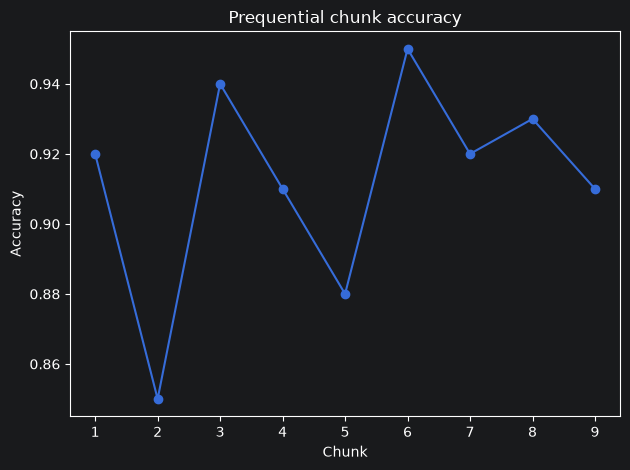

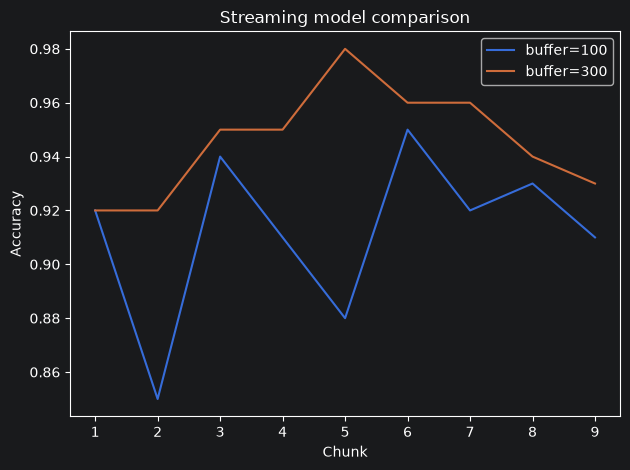

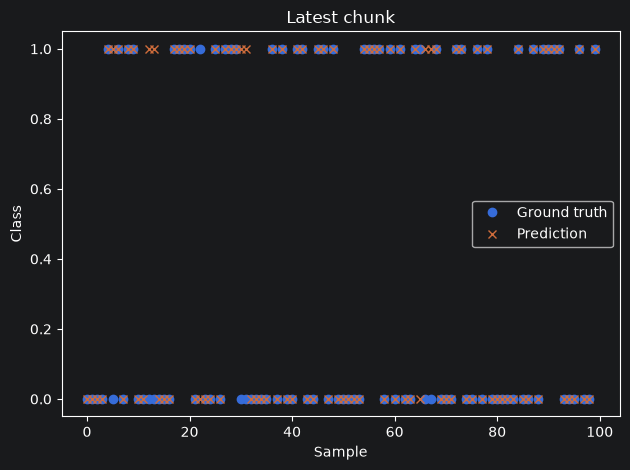

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Latest chunk'}, xlabel='Sample', ylabel='Class'>)

In [5]:
plot_metric_over_time(histories[0], 'Prequential chunk accuracy', 'Accuracy', show=True)
compare_models(*histories, labels=('buffer=100', 'buffer=300'), show=True)
# Show stored pre-training predictions for the latest evaluated chunk.
y_true = trainers[0].metrics._true[-100:]
y_pred = trainers[0].metrics._pred[-100:]
plot_predictions_vs_ground_truth(y_true, y_pred, show=True)

## Interpretation
The initial 300 rows are excluded from scoring. Each remaining row is scored once, before training. Logs report chunk accuracy, cumulative accuracy, update time, and serialized model memory. Buffer sizes trade update frequency against the amount of data available to each rebuilt tree.